<a href="https://colab.research.google.com/github/VishnuCodes96/Rebounce-Applied-AI-and-Analytics-Codes/blob/main/MP6_AspirationalDistricts.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Importing the libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Loading & understanding the Data

In [2]:
from google.colab import files
uploaded = files.upload()

Saving mp6_census2011_districts_aspirational.csv to mp6_census2011_districts_aspirational (1).csv


In [3]:
df = pd.read_csv("mp6_census2011_districts_aspirational.csv")
df.head()

,district_code,state,district,population,female_population,literate,female_literate,workers,female_workers,cultivators,...,hh_electric_lighting,hh_lpg_png,hh_internet,hh_latrine_in_premises,hh_tap_water,hh_television,hh_phone,hh_dilapidated_house,graduates,is_aspirational
0,1,JAMMU AND KASHMIR,Kupwara,870354,396164,439654,156831,229064,38165,34680,...,83071,15828,762,54335,50339,26828,56495,8463,21751,1
1,2,JAMMU AND KASHMIR,Badgam,753745,355704,335649,127908,214866,52288,55299,...,90190,15118,1999,83615,73303,54170,72197,3733,27950,0
2,3,JAMMU AND KASHMIR,Leh(Ladakh),133487,54516,93770,30936,75079,21814,20869,...,17250,13645,574,18780,6254,13597,13836,371,6197,0
3,4,JAMMU AND KASHMIR,Kargil,140802,63017,86236,29935,51873,12034,8266,...,15824,3285,235,17649,10769,8008,10562,575,3077,0
4,5,JAMMU AND KASHMIR,Punch,476835,224936,261724,98391,161393,43716,54264,...,62900,13160,346,16586,43697,16022,36358,2047,13962,0


In [4]:
print(f"Number of rows:{df.shape[0]}\nNumber of columns:{df.shape[1]}")

Number of rows:640
Number of columns:23


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 640 entries, 0 to 639
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   district_code           640 non-null    int64 
 1   state                   640 non-null    object
 2   district                640 non-null    object
 3   population              640 non-null    int64 
 4   female_population       640 non-null    int64 
 5   literate                640 non-null    int64 
 6   female_literate         640 non-null    int64 
 7   workers                 640 non-null    int64 
 8   female_workers          640 non-null    int64 
 9   cultivators             640 non-null    int64 
 10  agricultural_labourers  640 non-null    int64 
 11  households              640 non-null    int64 
 12  rural_households        640 non-null    int64 
 13  hh_electric_lighting    640 non-null    int64 
 14  hh_lpg_png              640 non-null    int64 
 15  hh_int

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
district_code,640.0,3.205000e+02,1.848964e+02,1.0,160.75,320.5,480.25,640.0
population,640.0,1.891961e+06,1.544380e+06,8004.0,817861.00,1557367.0,2583551.25,11060148.0
female_population,640.0,9.181011e+05,7.449864e+05,3590.0,401745.75,758920.0,1264276.75,5195070.0
literate,640.0,1.193186e+06,1.068583e+06,4436.0,482598.25,957346.5,1602260.25,8227161.0
female_literate,640.0,5.138675e+05,4.801816e+05,1822.0,200892.00,403859.0,664155.00,3635765.0
workers,640.0,7.529514e+05,6.071622e+05,3555.0,328468.75,622341.0,1036543.75,4492767.0
female_workers,640.0,2.342953e+05,1.913541e+05,1327.0,94203.50,192926.5,316365.75,1239177.0
cultivators,640.0,1.856387e+05,1.514895e+05,0.0,74910.25,150125.0,255301.50,1013050.0
agricultural_labourers,640.0,2.255513e+05,2.216222e+05,0.0,52841.75,164530.0,325898.25,1227956.0
households,640.0,5.169309e+05,4.417897e+05,3230.0,231362.00,414075.0,701952.50,3618151.0


### Checking for missing values

In [7]:
df.isnull().sum()

,0
district_code,0
state,0
district,0
population,0
female_population,0
literate,0
female_literate,0
workers,0
female_workers,0
cultivators,0


### Key Observations:
1. The dataset contains **640 districts and 23 columns.**
2. There are 21 numerical columns (`int64`) and 2 categorical columns (`object`).
3. The dataset contains demographic, employment and household-level information from Census 2011.
4. `is_aspirational` appears to be the target variable for our binary classification problem.
5. There are no missing values, so missing-value imputation is not required at this stage.

### Counting the districts in each category

In [8]:
df['is_aspirational'].value_counts()

,count
is_aspirational,
0,530
1,110


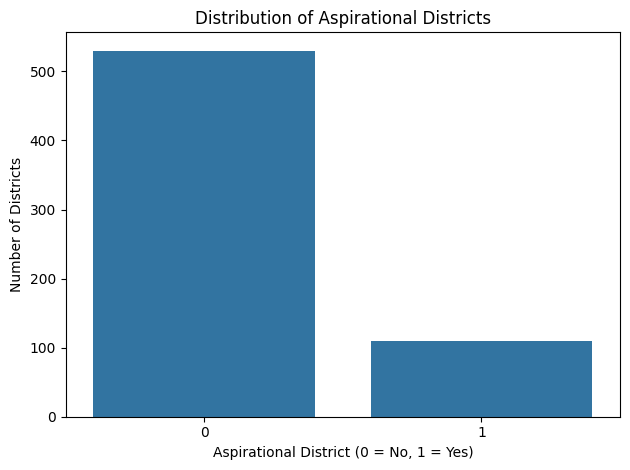

In [9]:
sns.countplot(data=df, x='is_aspirational')

plt.title('Distribution of Aspirational Districts')
plt.xlabel('Aspirational District (0 = No, 1 = Yes)')
plt.ylabel('Number of Districts')
plt.tight_layout()
plt.show()

In [10]:
aspirational_districts_percentage = round(df[df['is_aspirational'] == 1].shape[0] / df.shape[0] * 100,2)
print(f"Aspirational districts percentage: {aspirational_districts_percentage}%")
print(f"Not Aspirational districts percentage: {100 - aspirational_districts_percentage}%")

Aspirational districts percentage: 17.19%
Not Aspirational districts percentage: 82.81%


The dataset contains 640 districts, of which 110 (17.19%) are aspirational and 530 (82.81%) are non-aspirational. This indicates a significant class imbalance, with non-aspirational districts representing approximately 82.81% of the observations.

### Which states have the most aspirational districts?

In [11]:
aspirational_by_state = (
    df[df['is_aspirational'] == 1]
    .groupby('state')
    .size()
    .sort_values(ascending=False)
)

aspirational_by_state

,0
state,
JHARKHAND,19
BIHAR,13
ORISSA,10
CHHATTISGARH,8
MADHYA PRADESH,8
UTTAR PRADESH,8
ASSAM,7
ANDHRA PRADESH,6
RAJASTHAN,5


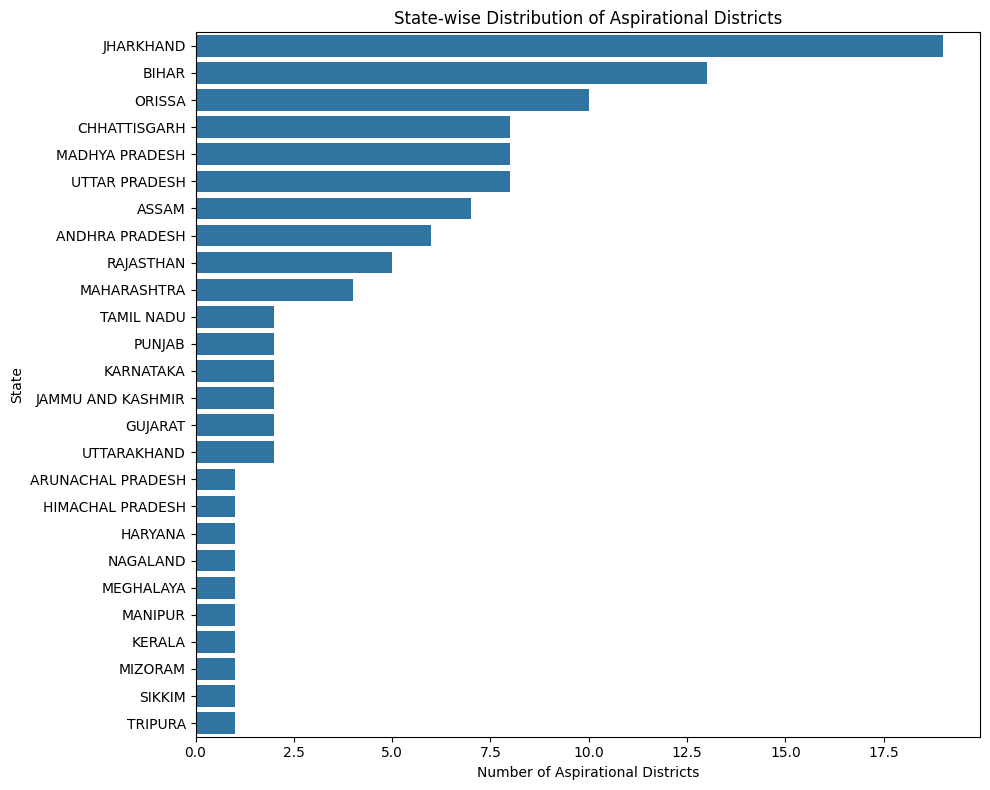

In [12]:
plt.figure(figsize=(10, 8))

sns.barplot(
    x=aspirational_by_state.values,
    y=aspirational_by_state.index
)

plt.title('State-wise Distribution of Aspirational Districts')
plt.xlabel('Number of Aspirational Districts')
plt.ylabel('State')
plt.tight_layout()
plt.show()

## Building fair features

### Creating `literacy_rate` Feature

In [13]:
df['literacy_rate'] = df['literate'] / df['population']
df[['district', 'population', 'literate', 'literacy_rate']].head()

,district,population,literate,literacy_rate
0,Kupwara,870354,439654,0.505144
1,Badgam,753745,335649,0.445308
2,Leh(Ladakh),133487,93770,0.702465
3,Kargil,140802,86236,0.612463
4,Punch,476835,261724,0.548877


### Creating `female_literacy_rate` Feature

In [14]:
df['female_literacy_rate'] = df['female_literate'] / df['female_population']
df[['district', 'female_population','female_literate', 'female_literacy_rate']].head()

,district,female_population,female_literate,female_literacy_rate
0,Kupwara,396164,156831,0.395874
1,Badgam,355704,127908,0.359591
2,Leh(Ladakh),54516,30936,0.567466
3,Kargil,63017,29935,0.475031
4,Punch,224936,98391,0.437418


### Creating `female_work_rate` Feature

In [15]:
df['female_work_rate'] = df['female_workers'] / df['female_population']
df[['district', 'female_population', 'female_workers', 'female_work_rate']].head()

,district,female_population,female_workers,female_work_rate
0,Kupwara,396164,38165,0.096336
1,Badgam,355704,52288,0.146999
2,Leh(Ladakh),54516,21814,0.400139
3,Kargil,63017,12034,0.190964
4,Punch,224936,43716,0.194349


### Creating `agri_labour_share` Feature

In [16]:
df['agri_labour_share'] = df['agricultural_labourers'] / df['workers']
df[['district','agricultural_labourers','workers','agri_labour_share']].head()

,district,agricultural_labourers,workers,agri_labour_share
0,Kupwara,56759,229064,0.247787
1,Badgam,36630,214866,0.170478
2,Leh(Ladakh),1645,75079,0.021910
3,Kargil,3763,51873,0.072543
4,Punch,31583,161393,0.195690


### Creating `rural_share` Feature

In [17]:
df['rural_share'] = df['rural_households'] / df['households']
df[['district', 'rural_households', 'households', 'rural_share']].head()

,district,rural_households,households,rural_share
0,Kupwara,158438,181664,0.872149
1,Badgam,160649,187839,0.855248
2,Leh(Ladakh),36920,54394,0.678751
3,Kargil,40370,48144,0.838526
4,Punch,132139,147408,0.896417


### Creating `electricity_share` Feature

In [18]:
df['electricity_share'] = df['hh_electric_lighting'] / df['households']
df[['district','hh_electric_lighting','households','electricity_share']].head()

,district,hh_electric_lighting,households,electricity_share
0,Kupwara,83071,181664,0.457278
1,Badgam,90190,187839,0.480145
2,Leh(Ladakh),17250,54394,0.317131
3,Kargil,15824,48144,0.328681
4,Punch,62900,147408,0.426707


### Creating `lpg_share` Feature

In [19]:
df['lpg_share'] = df['hh_lpg_png'] / df['households']
df[['district','hh_lpg_png','households','lpg_share']].head()

,district,hh_lpg_png,households,lpg_share
0,Kupwara,15828,181664,0.087128
1,Badgam,15118,187839,0.080484
2,Leh(Ladakh),13645,54394,0.250855
3,Kargil,3285,48144,0.068233
4,Punch,13160,147408,0.089276


### Creating `latrine_share` Feature

In [20]:
df['latrine_share'] = df['hh_latrine_in_premises'] / df['households']
df[['district', 'hh_latrine_in_premises', 'households', 'latrine_share']].head()

,district,hh_latrine_in_premises,households,latrine_share
0,Kupwara,54335,181664,0.299096
1,Badgam,83615,187839,0.445142
2,Leh(Ladakh),18780,54394,0.345259
3,Kargil,17649,48144,0.366588
4,Punch,16586,147408,0.112518


### Creating `tap_water_share` Feature

In [21]:
df['tap_water_share'] = df['hh_tap_water'] / df['households']
df[['district', 'hh_tap_water', 'households', 'tap_water_share']].head()

,district,hh_tap_water,households,tap_water_share
0,Kupwara,50339,181664,0.277099
1,Badgam,73303,187839,0.390244
2,Leh(Ladakh),6254,54394,0.114976
3,Kargil,10769,48144,0.223683
4,Punch,43697,147408,0.296436


### Creating `internet_share` Feature

In [22]:
df['internet_share'] = df['hh_internet'] / df['households']
df[['district', 'hh_internet', 'households', 'internet_share']].head()

,district,hh_internet,households,internet_share
0,Kupwara,762,181664,0.004195
1,Badgam,1999,187839,0.010642
2,Leh(Ladakh),574,54394,0.010553
3,Kargil,235,48144,0.004881
4,Punch,346,147408,0.002347


### why are rates better than raw counts?
**Ans:** Rates allow fair comparisons between districts of different population sizes by showing the relative proportion rather than being influenced by differences in raw population counts.

## Explore the two groups

In [23]:
features = [
    'literacy_rate',
    'female_literacy_rate',
    'female_work_rate',
    'agri_labour_share',
    'rural_share',
    'electricity_share',
    'lpg_share',
    'latrine_share',
    'tap_water_share',
    'internet_share'
]

group_comparison = df.groupby('is_aspirational')[features].mean()
# .mean() Calculates the average of each feature within each group

# .groupby('is_aspirational') Divides districts into groups 0 and 1

group_comparison.T.round(3)

is_aspirational,0,1
literacy_rate,0.642,0.539
female_literacy_rate,0.572,0.457
female_work_rate,0.276,0.320
agri_labour_share,0.250,0.368
rural_share,0.704,0.833
electricity_share,0.499,0.366
lpg_share,0.197,0.092
latrine_share,0.355,0.223
tap_water_share,0.325,0.171
internet_share,0.019,0.007


### Key Observations:
1. **Literacy differences**

Aspirational districts have lower average overall literacy (53.9%) compared to non-aspirational districts (64.2%). Female literacy also follows the same pattern, with a difference of 11.5 percentage points.

2. **Female workforce participation**

Aspirational districts have a higher female work rate (32%) compared to non-aspirational districts (27.6%). This is an interesting contrast, but a higher work rate does not necessarily indicate better employment opportunities or working conditions.

3. **Agricultural dependence**

Aspirational districts have a higher agricultural labour share (36.8%) compared to non-aspirational districts (25%). This suggests greater dependence on agricultural labour in these districts.

4. **Rural population concentration**

Aspirational districts have a higher rural share (83.3%) compared to non-aspirational districts (70.4%). This indicates that the selected districts are considerably more rural on average.

5. **Basic infrastructure and household amenities**

Aspirational districts have lower average shares across all five infrastructure-related features:
- Electricity: 36.6% vs 49.9%.
- LPG: 9.2% vs 19.7%.
- Latrine: 22.3% vs 35.5%.
- Tap water: 17.1% vs 32.5%.
- Internet: 0.7% vs 1.9%.

The differences suggest substantial disparities in household infrastructure and amenities.

### Key Insights:
* The comparison reveals noticeable differences between aspirational and non-aspirational districts. Aspirational districts have lower average literacy, female literacy, electricity, LPG, latrine, tap water and internet shares.

* However, they have higher female work rates, agricultural labour shares and rural population shares. The largest differences are observed in rural share, agricultural labour share and household infrastructure indicators.

* These patterns suggest that demographic characteristics and household amenities from Census 2011 may help distinguish aspirational districts from non-aspirational districts.

### Visualizing `literacy_rate`

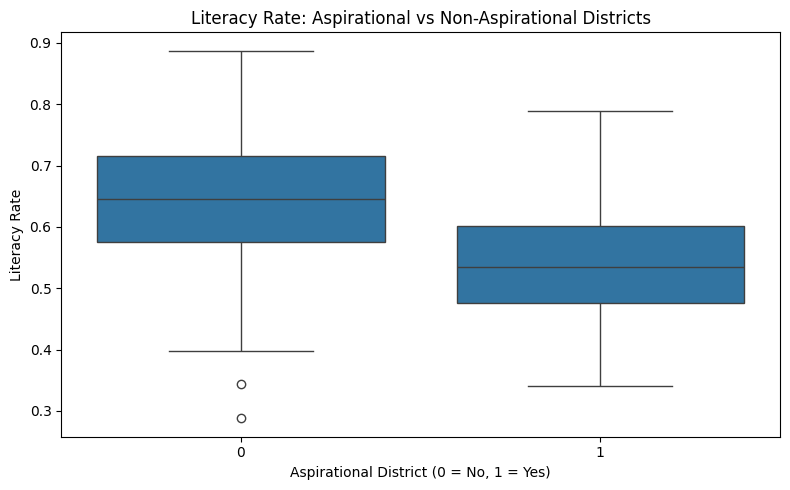

In [24]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='is_aspirational',
    y='literacy_rate'
)

plt.title('Literacy Rate: Aspirational vs Non-Aspirational Districts')
plt.xlabel('Aspirational District (0 = No, 1 = Yes)')
plt.ylabel('Literacy Rate')
plt.tight_layout()
plt.show()

### Interpretation:
* The box plot confirms that aspirational districts generally have lower literacy rates than non-aspirational districts. The median literacy rate is approximately 53.3% for aspirational districts compared to 64.5% for non-aspirational districts.

* Both groups exhibit considerable variation, with some overlap in their distributions. Two unusually low literacy-rate observations are also visible among non-aspirational districts.

* Therefore, literacy rate appears to be a useful distinguishing feature, but it cannot independently separate the two groups.

### Which three features show the biggest difference between the groups?

In [25]:
feature_differences = (group_comparison.loc[0] - group_comparison.loc[1]).abs().sort_values(ascending=False)
# Subtracts the average values of Group 1 from Group 0.
# .abs() converts the differences into positive values.
# .sort_values(ascending=False) arranges the features from largest difference to smallest.
feature_differences.head(3)

,0
tap_water_share,0.153866
electricity_share,0.133575
latrine_share,0.132461


### Key Insights:
* The three features showing the largest differences between aspirational and non-aspirational districts are **tap water share, electricity share and latrine share**. The differences are 15.4, 13.3 and 13.2 percentage points, respectively.

* Non-aspirational districts have higher average values across all three features, suggesting comparatively better household infrastructure and access to basic amenities.

* These features may be useful in distinguishing the two groups during classification.

## Baseline and logistic regression

### Setting X to the ten features engineered and y to `is_aspirational` column.

In [26]:
X = df[features]
y = df['is_aspirational']
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (640, 10)
y shape: (640,)


### Splitting whole dataset into train and test

In [27]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y # keeps the same share of 1s in train and test
)

In [28]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (480, 10)
X_test shape: (160, 10)
y_train shape: (480,)
y_test shape: (160,)


### Baseline: what accuracy would you get by predicting 0 for every district?

In [29]:
from sklearn.metrics import accuracy_score

# Predicting 0 for every district in the test set
baseline_pred = [0] * len(y_test)

# Calculating baseline accuracy
baseline_acc = accuracy_score(y_test, baseline_pred)

print("Baseline Accuracy:", baseline_acc)

Baseline Accuracy: 0.83125


### Note:
* A baseline accuracy of 83.13% was obtained by predicting every district in the test set as non-aspirational. Although this appears to be a reasonably high accuracy, the baseline fails to identify any aspirational districts.
* This demonstrates the limitations of accuracy as an evaluation metric for our imbalanced dataset.
* Therefore, we need to consider additional evaluation metrics, particularly precision and recall, when assessing our classification models.

### Scaling the features

In [30]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Training the Logistic Regression model

In [31]:
log_reg = LogisticRegression(max_iter=1000)

log_reg.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

### Predicting the test set

In [32]:
y_pred = log_reg.predict(X_test_scaled)

### Verifying the predictions

In [33]:
print("First 20 actual values:")
print(y_test.head(20).values)

print("\nFirst 20 predicted values:")
print(y_pred[:20])

First 20 actual values:
[0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0]

First 20 predicted values:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [34]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

# 2. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)

# 3. Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.85

Confusion Matrix:
[[129   4]
 [ 20   7]]

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.97      0.91       133
           1       0.64      0.26      0.37        27

    accuracy                           0.85       160
   macro avg       0.75      0.61      0.64       160
weighted avg       0.83      0.85      0.82       160



### Key findings:
* 129 True Negatives: Correctly identified 129 non-aspirational districts.
* 4 False Positives: Incorrectly flagged 4 non-aspirational districts as aspirational.
* 20 False Negatives: Failed to identify 20 actual aspirational districts.
* 7 True Positives: Correctly identified only 7 aspirational districts.

### Is the model's accuracy much better than the baseline? Why is accuracy a poor guide here? What is the recall for aspirational districts?

* The Logistic Regression model achieved 85% accuracy, compared with the baseline accuracy of 83.13%. Although this is an improvement, it is not substantial.
* Accuracy is a poor evaluation metric here because the dataset is imbalanced, with approximately 83% non-aspirational districts and only 17% aspirational districts.
* A model can achieve high accuracy by predicting mostly non-aspirational districts while failing to identify the aspirational ones.
* The recall for aspirational districts (class 1) is only 0.26 (26%), meaning the model identified just 7 out of 27 actual aspirational districts and missed the remaining 20.